# DSA5102 Snake — Member 2 Completed Report

        **Actor-Critic and behavior-cloning warm-up.** This independently runnable notebook covers Member 2 only. It includes executable model, training and gameplay implementations, saved experimental evidence and trained checkpoints. `TRAIN_MODEL=False` keeps training disabled; the saved seed-7 checkpoint is actually loaded and evaluated.

        Extract the entire `member2_snake` folder and launch Jupyter inside it. The integrated group notebook is a separate file; other members' pending sections are not represented as completed work here.

In [1]:
TRAIN_MODEL = False  # default: load the supplied trained checkpoints
import os, sys, json
from pathlib import Path
HERE = Path.cwd()
if not (HERE / 'member2_experiment.py').exists():
    raise FileNotFoundError('Open this notebook from the extracted member2_snake folder.')
os.environ.setdefault('MPLCONFIGDIR', str(HERE / '.mplconfig'))
os.environ.setdefault('PYGAME_HIDE_SUPPORT_PROMPT', '1')
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import Image as NotebookImage, display
from environment import SnakeEnv
from main import load_agent, evaluate_model
torch.set_num_threads(1)
RESULT_DIR = HERE / 'runs/member2/final'
assert (RESULT_DIR / 'results.json').is_file(), 'Extract the entire package, including runs/.'
print('TRAIN_MODEL =', TRAIN_MODEL, '| device: CPU | inference only by default')

TRAIN_MODEL = False | device: CPU | inference only by default


# 2. Actor-Critic with Behavior-Cloning Warm-Up

> **Owner:** Member 2. Scope: `model.py`, `main.py`, `play.py`, the BC ablation, and this notebook section.
> Member 1's environment and teacher implementations are reused unchanged. Member 3's DQN results are not included as new Member 2 experiments.

## 2.1 Motivation and Research Question

Snake gives useful positive rewards only when food is reached or the game is won. A randomly initialized policy often collides before reaching food, leaving a weak learning signal. We ask whether **100 episodes of supervised teacher demonstrations improve a one-step Actor-Critic agent compared with no behavior-cloning (BC) warm-up**, given the same subsequent autonomous interaction budget.

The comparison is **AC from scratch versus BC + AC**. BC has additional demonstration and optimization costs, so we describe it as an assisted initialization experiment, not equal-total-compute training. We also evaluate the saved BC-only and last-AC stages to distinguish imitation gains from later RL gains.

## 2.2 Shared Network and Algorithm

Both conditions use exactly the same network and paired initial weights:

```text
observation [batch, 7, 8, 8]
  -> Conv2d(7, 16, kernel=3, padding=1) -> ReLU -> Flatten [batch, 1024]
  -> actor: Linear(1024, 3) -> categorical action distribution
  -> critic: Linear(1024, 1) -> state-value estimate V(s)
```

There are **5,124 trainable parameters**. Actions follow Member 1's convention: 0 = left, 1 = right, 2 = straight. Training samples from the current policy; validation, test and animation use greedy actions. No teacher override, collision mask or search is used in learned-agent evaluation.

### 2.2.1 Behavior cloning

During warm-up, we explicitly ask Member 1's BFS teacher for an action, execute that same action, and store the `(observation, teacher action)` pair in a demonstration buffer with capacity 10,000. At every teacher transition, four mini-batches of up to 64 examples are sampled and optimized using categorical cross-entropy:

$$L_{BC}=-\frac{1}{B}\sum_{i=1}^B \log\pi_\theta(a_i^T\mid s_i).$$

The actor head and shared convolutional features are trained. The critic receives no direct supervised/value loss during BC. This makes the treatment specifically imitation warm-up. The original group's `value_update()` remains available for compatibility, but this experiment does not call it in warm-up. After the 100 teacher episodes, teacher queries and BC updates stop completely.

A high teacher trajectory score is not a learned-policy score: the teacher chooses those actions. We therefore evaluate the neural network independently immediately after BC (`post_bc.pt`).

### 2.2.2 One-step Actor-Critic

For a transition sampled by the current policy, we compute:

$$y_t = r_t+\gamma(1-z_t)\operatorname{stopgrad}[V_\phi(s_{t+1})],\qquad A_t=y_t-V_\phi(s_t).$$

Here $z_t$ is `terminated`: collision or success. An external 300-step limit is a `truncated` episode; it ends the rollout but still bootstraps the value of the final observation, following Gymnasium's time-limit convention. The remaining budget is not observed, so this is a continuing-task value approximation with capped evaluation episodes.

The minimized loss is:

$$L = \underbrace{-\log\pi_\theta(a_t\mid s_t)\operatorname{stopgrad}(A_t)}_{\text{actor}} + \underbrace{\tfrac12(y_t-V_\phi(s_t))^2}_{\text{critic}} - \underbrace{\beta H(\pi_\theta(\cdot\mid s_t))}_{\text{entropy bonus}}.$$

A positive advantage increases the probability of the selected action, while a negative advantage decreases it. Detaching the advantage prevents the actor term from using the critic as a shortcut; detaching the target prevents gradients through the next-state estimate. The critic fits the bootstrapped target. Entropy regularization encourages exploration; gradient norm clipping at 1.0 limits large updates. This is a compact, one-step on-policy AC implementation, without PPO clipping, GAE, or DQN replay.

### Executable model implementation

The following is the complete `model.py` implementation, including the actor/critic losses and BC update.

In [2]:
"""Member 2: one-step Actor-Critic and supervised behavior cloning.

Architecture and public checkpoint interface are compatible with the group code.
The `done` argument means a true terminal state, not a time-limit truncation.
"""

from __future__ import annotations

from pathlib import Path
from typing import Any

import torch
import torch.nn as nn
import torch.nn.functional as F


class ConvActorCritic(nn.Module):
    """A compact shared encoder with categorical actor and state-value critic."""

    def __init__(
        self,
        input_channels: int,
        output_dim: int,
        grid_size: int,
        lr: float = 1e-4,
        weight_decay: float = 1e-5,
        entropy_coef: float = 0.01,
    ) -> None:
        super().__init__()
        self.input_channels = input_channels
        self.output_dim = output_dim
        self.grid_size = grid_size
        self.entropy_coef = entropy_coef
        feature_dim = 16 * grid_size * grid_size
        self.feature_extractor = nn.Sequential(
            nn.Conv2d(input_channels, 16, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Flatten(),
        )
        self.actor = nn.Linear(feature_dim, output_dim)
        self.critic = nn.Linear(feature_dim, 1)
        self.optimizer = torch.optim.Adam(
            self.parameters(),
            lr=lr,
            weight_decay=weight_decay,
        )

    def forward(self, observation: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        features = self.feature_extractor(observation)
        logits = self.actor(features)
        value = self.critic(features).squeeze(-1)
        return logits, value

    @torch.no_grad()
    def predict(self, observation: torch.Tensor, deterministic: bool = False) -> int:
        logits, _ = self(observation)
        distribution = torch.distributions.Categorical(logits=logits)
        action = torch.argmax(logits, dim=-1) if deterministic else distribution.sample()
        return int(action.item())

    @staticmethod
    def td_target(reward, next_value, done, gamma=0.99):
        """Stop gradients through the bootstrap; supports scalar or batched inputs."""
        with torch.no_grad():
            r = torch.as_tensor(reward, dtype=next_value.dtype, device=next_value.device)
            terminal = torch.as_tensor(done, dtype=next_value.dtype, device=next_value.device)
            return r + gamma * (1.0 - terminal) * next_value

    def update(
        self,
        state: torch.Tensor,
        action: int | torch.Tensor,
        reward: float,
        next_state: torch.Tensor,
        done: bool,
        gamma: float = 0.99,
    ) -> dict[str, float]:
        """Minimize -log pi(a|s) * stopgrad(A) + 0.5*A^2 - beta*H(pi)."""

        logits, value = self(state)
        with torch.no_grad():
            _, next_value = self(next_state)
            target = self.td_target(reward, next_value, done, gamma)

        action_tensor = torch.as_tensor(action, dtype=torch.long, device=value.device).reshape(-1)
        distribution = torch.distributions.Categorical(logits=logits)
        log_probability = distribution.log_prob(action_tensor)
        advantage = target - value
        actor_loss = -(log_probability * advantage.detach()).mean()
        critic_loss = 0.5 * advantage.square().mean()
        entropy = distribution.entropy().mean()
        loss = actor_loss + critic_loss - self.entropy_coef * entropy

        self.optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(self.parameters(), max_norm=1.0)
        self.optimizer.step()
        return {
            "loss": float(loss.detach()),
            "actor_loss": float(actor_loss.detach()),
            "critic_loss": float(critic_loss.detach()),
            "entropy": float(entropy.detach()),
            "advantage": float(advantage.detach().mean()),
        }

    def imitation_update(
        self,
        state: torch.Tensor,
        teacher_action: int | torch.Tensor,
    ) -> float:
        """Learn an explicitly supplied teacher action with behavior cloning."""

        logits, _ = self(state)
        target = torch.as_tensor(
            teacher_action,
            dtype=torch.long,
            device=logits.device,
        ).reshape(-1)
        loss = F.cross_entropy(logits, target)
        self.optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(self.parameters(), max_norm=1.0)
        self.optimizer.step()
        return float(loss.detach())

    def value_update(
        self,
        state: torch.Tensor,
        reward: float,
        next_state: torch.Tensor,
        done: bool,
        gamma: float = 0.99,
    ) -> float:
        """Train the critic on a teacher transition without a policy-gradient update."""

        _, value = self(state)
        with torch.no_grad():
            _, next_value = self(next_state)
            target = self.td_target(reward, next_value, done, gamma)
        loss = 0.5 * (target - value).square().mean()
        self.optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(self.parameters(), max_norm=1.0)
        self.optimizer.step()
        return float(loss.detach())

    def save_checkpoint(
        self,
        filename: str | Path,
        *,
        episode: int,
        config: dict[str, Any],
    ) -> None:
        path = Path(filename)
        path.parent.mkdir(parents=True, exist_ok=True)
        torch.save(
            {
                "model_state_dict": self.state_dict(),
                "optimizer_state_dict": self.optimizer.state_dict(),
                "episode": episode,
                "config": config,
            },
            path,
        )

    def load_checkpoint(self, filename: str | Path) -> dict[str, Any]:
        checkpoint = torch.load(filename, map_location=self.device, weights_only=True)
        self.load_state_dict(checkpoint["model_state_dict"])
        if "optimizer_state_dict" in checkpoint:
            self.optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
        return {
            "episode": int(checkpoint.get("episode", -1)),
            "config": dict(checkpoint.get("config", {})),
        }

    @property
    def device(self) -> torch.device:
        return next(self.parameters()).device

In [3]:
env_ac = SnakeEnv(grid_size=8, end_score=8, max_steps=300)
agent_ac = ConvActorCritic(7, 3, 8)
print(agent_ac)
print('Trainable parameters:', sum(p.numel() for p in agent_ac.parameters()))
sample_obs, _ = env_ac.reset(seed=42)
logits, value = agent_ac(torch.from_numpy(sample_obs).unsqueeze(0))
print('Actor logits shape:', tuple(logits.shape), '| critic shape:', tuple(value.shape))
env_ac.close()

ConvActorCritic(
  (feature_extractor): Sequential(
    (0): Conv2d(7, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Flatten(start_dim=1, end_dim=-1)
  )
  (actor): Linear(in_features=1024, out_features=3, bias=True)
  (critic): Linear(in_features=1024, out_features=1, bias=True)
)
Trainable parameters: 5124
Actor logits shape: (1, 3) | critic shape: (1,)


## 2.3 Experimental Protocol

| Setting | Frozen value |
|---|---|
| Environment | Member 1's unchanged `SnakeEnv`; 8 × 8; target length 8; score ceiling 7 |
| Reward / teacher | sparse / BFS shortest-path |
| Episode time limit | 300 steps |
| Training seeds | 7, 42, 2026, 31415, 27182 |
| Conditions | `teacher_episodes=0` and `teacher_episodes=100` |
| Autonomous RL budget | exactly 50,000 transitions per model; 10 models total |
| Additional demonstrations | 100 teacher episodes only for BC + AC; counted separately |
| Optimizer | Adam, learning rate 1e-4, weight decay 1e-5 |
| Discount / entropy coefficient | gamma = 0.99 / beta = 0.01 |
| Validation | 30 greedy episodes, seeds 500000–500029, every 5,000 AC steps |
| Checkpoint selection | highest validation mean score, then success rate, then reward; earliest exact tie |
| Final test | 200 greedy episodes/model, seeds 900000–900199 |
| Runtime | CPU, one PyTorch thread; versions recorded in `versions.json` |

Both conditions start from the same weights within a seed. Their autonomous phase starts from the same random-number seed and environment reset-seed sequence. Once their actions differ, their visited states and episode lengths naturally differ. We pair by training seed, not by matching every state.

The original `episodes=500, teacher_episodes=100` API means 100 teacher episodes followed by 400 AC episodes. That gives different interaction counts across conditions. We retain that API for compatibility, but **the reported ablation uses `rl_steps=50000`**, so `episodes` does not limit the autonomous phase. The last training trajectory may end at the overall budget before the game finishes; it is marked `budget_partial` in the log and is never counted as a completed test episode.

Validation uses an independent environment and cannot change training weights. The final test is run only after checkpoint selection. The post-BC and latest checkpoints are additional, predeclared stage diagnostics; they are not selected by test performance. Baselines are evaluated on the same 200 test seeds with a separately seeded random-action generator.

### Executable training and evaluation implementation

This is the complete library portion of `main.py`. Defining these functions does not train a model. The paired driver below calls the same saved module.

In [4]:
"""Member 2: explicit BC warm-up, then unassisted on-policy Actor-Critic.

`episodes` retains the original TOTAL-episode API when rl_steps is None.
For the paired experiment, rl_steps fixes the AC interaction budget independently
of the optional teacher episodes. CSV files are sufficient to replot every curve.
"""
from __future__ import annotations
import argparse
import csv
import json
import random
import time
from dataclasses import asdict, dataclass
from pathlib import Path
import numpy as np
import torch
from environment import SnakeEnv
from model import ConvActorCritic


@dataclass(slots=True)
class TrainConfig:
    episodes: int = 500
    teacher_episodes: int = 100
    imitation_updates: int = 4
    grid_size: int = 8
    end_score: int = 8
    max_steps: int = 300
    rl_steps: int | None = None
    eval_interval: int = 100           # episodes in original API
    eval_every_steps: int = 5000       # step-budget mode
    eval_episodes: int = 30
    validation_seed_base: int = 500000
    save_interval: int = 250
    learning_rate: float = 1e-4
    weight_decay: float = 1e-5
    gamma: float = 0.99
    entropy_coef: float = 0.01
    seed: int = 42
    device: str = 'cpu'
    output_dir: Path = Path('runs/snake')
    resume: Path | None = None
    tensorboard: bool = False
    reward_mode: str = 'sparse'
    teacher_mode: str = 'shortest_path'
    torch_threads: int = 1

    def validate(self):
        if self.episodes < 1 or self.teacher_episodes < 0:
            raise ValueError('episodes must be positive and teacher_episodes nonnegative')
        if self.rl_steps is None and self.teacher_episodes >= self.episodes:
            raise ValueError('leave at least one AC episode after the teacher phase')
        if self.rl_steps is not None and self.rl_steps < 1:
            raise ValueError('rl_steps must be positive')
        if self.imitation_updates < 1 or self.eval_episodes < 1 or self.torch_threads < 1:
            raise ValueError('updates, evaluation episodes and threads must be positive')
        if min(self.eval_interval, self.save_interval) < 0 or self.eval_every_steps < 1:
            raise ValueError('invalid interval')
        if not 0 <= self.gamma <= 1 or self.learning_rate <= 0 or self.weight_decay < 0:
            raise ValueError('invalid optimizer/discount configuration')
        if self.resume is not None:
            raise ValueError('Exact mid-run resume is unsupported; rerun incomplete runs in a fresh directory.')

    def checkpoint_payload(self):
        payload = asdict(self)
        payload['output_dir'] = str(self.output_dir)
        payload['resume'] = None
        return payload


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def choose_device(requested='auto'):
    if requested == 'auto':
        requested = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
    device = torch.device(requested)
    if device.type == 'cuda' and not torch.cuda.is_available():
        raise RuntimeError('CUDA is unavailable')
    if device.type == 'mps' and not torch.backends.mps.is_available():
        raise RuntimeError('MPS is unavailable')
    return device


def as_tensor(observation, device):
    return torch.as_tensor(observation, dtype=torch.float32, device=device).unsqueeze(0)


def make_env(config, **kwargs):
    return SnakeEnv(grid_size=config.grid_size, end_score=config.end_score,
                    max_steps=config.max_steps, reward_mode=config.reward_mode,
                    teacher_mode=config.teacher_mode, **kwargs)


@torch.no_grad()
def evaluate_model(agent, config, device=None, *, seed_offset=None, seed_base=None,
                   episodes=None, return_episodes=False):
    """Independent greedy rollouts: no teacher, no action masking, no updates."""
    device = device or agent.device
    seed_base = (config.seed + seed_offset if seed_offset is not None else
                 config.validation_seed_base) if seed_base is None else seed_base
    count = episodes or config.eval_episodes
    env = make_env(config)
    was_training = agent.training
    agent.eval()
    rows = []
    try:
        for ep in range(count):
            obs, _ = env.reset(seed=seed_base + ep)
            total_reward = 0.0
            while True:
                action = agent.predict(as_tensor(obs, device), deterministic=True)
                obs, reward, terminated, truncated, info = env.step(action)
                total_reward += reward
                if terminated or truncated:
                    won = info['length'] >= config.end_score
                    rows.append(dict(episode_seed=seed_base+ep, reward=total_reward,
                                     score=int(info['score']), steps=int(info['steps']),
                                     success=int(won), death=int(terminated and not won),
                                     truncated=int(truncated)))
                    break
    finally:
        env.close()
        agent.train(was_training)
    result = {key: float(np.mean([r[key] for r in rows]))
              for key in ['reward', 'score', 'steps', 'success', 'death', 'truncated']}
    result['success_rate'] = result.pop('success')
    result['death_rate'] = result.pop('death')
    result['truncation_rate'] = result.pop('truncated')
    if return_episodes:
        return result, rows
    return result


def load_agent(checkpoint_path, device='cpu'):
    device = choose_device(device) if isinstance(device, str) else device
    payload = torch.load(checkpoint_path, map_location=device, weights_only=True)
    cfg = payload['config']
    agent = ConvActorCritic(7, 3, int(cfg['grid_size']),
                            lr=cfg.get('learning_rate', 1e-4),
                            weight_decay=cfg.get('weight_decay', 1e-5),
                            entropy_coef=cfg.get('entropy_coef', .01)).to(device)
    agent.load_checkpoint(checkpoint_path)
    agent.eval()
    fields = TrainConfig.__dataclass_fields__
    config = TrainConfig(**{k: v for k, v in cfg.items() if k in fields})
    return agent, config


def write_csv(path, rows):
    if not rows:
        return
    with Path(path).open('w', newline='', encoding='utf-8') as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def train(config):
    config.validate()
    config.output_dir = Path(config.output_dir)
    if (config.output_dir/'summary.json').exists():
        raise FileExistsError(f'Completed run exists: {config.output_dir}; choose a fresh output directory')
    torch.set_num_threads(config.torch_threads)
    seed_everything(config.seed)
    device = choose_device(config.device)
    out = config.output_dir
    checkpoints = out/'checkpoints'
    checkpoints.mkdir(parents=True, exist_ok=True)
    (out/'config.json').write_text(json.dumps(config.checkpoint_payload(), indent=2))
    env = make_env(config)
    agent = ConvActorCritic(7, 3, config.grid_size, config.learning_rate,
                            config.weight_decay, config.entropy_coef).to(device)
    writer = None
    if config.tensorboard:
        from torch.utils.tensorboard import SummaryWriter
        writer = SummaryWriter(out/'tensorboard')
    start = time.perf_counter()
    history, validations = [], []
    demo_steps = rl_steps = bc_updates = 0
    best_key = (-float('inf'),)*3
    selected_step = 0
    payload = config.checkpoint_payload()
    def save(name, episode):
        agent.save_checkpoint(checkpoints/name, episode=episode,
                              config={**payload, 'progress_rl_steps': rl_steps,
                                      'progress_demo_steps': demo_steps})
    def validate(stage, episode, selectable=True):
        nonlocal best_key, selected_step
        stats = evaluate_model(agent, config, device)
        row = dict(stage=stage, episode=episode, rl_steps=rl_steps,
                   demo_steps=demo_steps, total_steps=demo_steps+rl_steps, **stats)
        validations.append(row)
        write_csv(out/'validation.csv', validations)
        key = (stats['score'], stats['success_rate'], stats['reward'])
        if selectable and key > best_key:
            best_key, selected_step = key, rl_steps
            save('best.pt', episode)
        print(f"seed={config.seed} BC={config.teacher_episodes} {stage} AC_steps={rl_steps} "
              f"val_score={stats['score']:.3f} success={stats['success_rate']:.1%}", flush=True)
        return stats
    def log_episode(phase, ep, info, reward, metrics, truncated, terminated, seconds):
        row = dict(phase=phase, episode=ep, rl_steps=rl_steps, demo_steps=demo_steps,
                   total_steps=rl_steps+demo_steps, reward=reward, score=int(info['score']),
                   steps=int(info['steps']), success=int(info['length'] >= config.end_score),
                   terminated=int(terminated), truncated=int(truncated),
                   loss=metrics.get('loss', ''), actor_loss=metrics.get('actor_loss', ''),
                   critic_loss=metrics.get('critic_loss', ''), entropy=metrics.get('entropy', ''),
                   bc_loss=metrics.get('bc_loss', ''), seconds=seconds,
                   budget_partial=int(phase == 'actor_critic' and not (terminated or truncated)))
        history.append(row)
        if writer:
            for key in ['score', 'reward']:
                writer.add_scalar(f'{phase}/{key}', row[key], row['total_steps'])
    try:
        save('initial.pt', -1)
        validate('initial', -1, False)
        # Store explicit (state, teacher action) pairs; only CE is used in warm-up.
        demonstrations = []
        demo_rng = random.Random(config.seed)
        for episode in range(config.teacher_episodes):
            obs, _ = env.reset(seed=100000 + config.seed*1000 + episode)
            total, losses = 0.0, []
            ep_start = time.perf_counter()
            while True:
                action = env.teacher_action()
                demonstrations.append((obs.copy(), action))
                if len(demonstrations) > 10000:
                    demonstrations.pop(0)
                nxt, reward, terminated, truncated, info = env.step(action)
                for _ in range(config.imitation_updates):
                    batch = demo_rng.sample(demonstrations, min(64, len(demonstrations)))
                    states = torch.as_tensor(np.stack([x[0] for x in batch]), device=device)
                    actions = torch.tensor([x[1] for x in batch], device=device)
                    losses.append(agent.imitation_update(states, actions))
                    bc_updates += 1
                demo_steps += 1
                total += reward
                obs = nxt
                if terminated or truncated:
                    break
            log_episode('teacher', episode, info, total,
                        {'bc_loss': float(np.mean(losses))}, truncated, terminated,
                        time.perf_counter()-ep_start)
        bc_seconds = time.perf_counter()-start
        save('post_bc.pt', config.teacher_episodes-1)
        if config.teacher_episodes:
            validate('post_bc', config.teacher_episodes-1, False)
        # Give the two arms the same RL environment seed sequence and RNG start.
        seed_everything(config.seed + 10000)
        episode = 0
        next_eval = config.eval_every_steps
        halfway_saved = False
        while config.rl_steps is not None or episode < config.episodes-config.teacher_episodes:
            obs, _ = env.reset(seed=config.seed*1000 + episode)
            total, metrics_list = 0.0, []
            ep_start = time.perf_counter()
            while True:
                state = as_tensor(obs, device)
                action = agent.predict(state)        # sample current policy, NO teacher
                nxt, reward, terminated, truncated, info = env.step(action)
                # Gymnasium time limits bootstrap V(next); true wins/deaths do not.
                metrics_list.append(agent.update(state, action, reward,
                                                 as_tensor(nxt, device), terminated, config.gamma))
                rl_steps += 1
                total += reward
                obs = nxt
                if config.rl_steps and not halfway_saved and rl_steps >= config.rl_steps//2:
                    save('midpoint.pt', config.teacher_episodes+episode)
                    halfway_saved = True
                if config.rl_steps and rl_steps >= next_eval:
                    validate('actor_critic', config.teacher_episodes+episode)
                    next_eval += config.eval_every_steps
                budget_end = config.rl_steps is not None and rl_steps >= config.rl_steps
                if terminated or truncated or budget_end:
                    break
            metrics = {k: float(np.mean([r[k] for r in metrics_list])) for k in metrics_list[0]}
            log_episode('actor_critic', config.teacher_episodes+episode, info, total, metrics,
                        truncated, terminated, time.perf_counter()-ep_start)
            episode += 1
            if episode % 25 == 0 or budget_end:
                write_csv(out/'history.csv', history)
            if config.rl_steps is None and config.eval_interval and episode % config.eval_interval == 0:
                validate('actor_critic', config.teacher_episodes+episode-1)
            if config.rl_steps is None and config.save_interval and episode % config.save_interval == 0:
                save(f'episode-{config.teacher_episodes+episode}.pt', config.teacher_episodes+episode-1)
            if budget_end:
                break
        if not validations or validations[-1]['rl_steps'] != rl_steps or selected_step == 0:
            validate('actor_critic', config.teacher_episodes+episode-1)
        save('latest.pt', config.teacher_episodes+episode-1)
        write_csv(out/'history.csv', history)
        write_csv(out/'validation.csv', validations)
        summary = dict(config=config.checkpoint_payload(), rl_steps=rl_steps, demo_steps=demo_steps,
                       total_steps=rl_steps+demo_steps, bc_updates=bc_updates,
                       ac_updates=rl_steps, ac_episodes=episode,
                       best_validation_score=best_key[0], selected_rl_steps=selected_step,
                       bc_seconds=bc_seconds, training_seconds=time.perf_counter()-start,
                       device=str(device), checkpoint=str(checkpoints/'best.pt'))
        (out/'summary.json').write_text(json.dumps(summary, indent=2))
        return summary
    finally:
        env.close()
        if writer:
            writer.close()

In [5]:
from member2_experiment import run_experiment
if TRAIN_MODEL:
    # Equal RL-step budgets, teacher_episodes=0 vs 100, paired seeds.
    # Completed matching runs are reused; select a new output directory for a fresh replication.
    run_experiment(RESULT_DIR, mode='final')
protocol_ac = json.loads((RESULT_DIR / 'protocol.json').read_text())
print(json.dumps({k: protocol_ac[k] for k in ['seeds', 'rl_steps', 'teacher_episodes', 'test_episodes']}, indent=2))
best_ac = RESULT_DIR / 'seed-7/bc_ac/checkpoints/best.pt'
agent_ac, config_ac = load_agent(best_ac, 'cpu')
check_ac = evaluate_model(agent_ac, config_ac, seed_base=900000, episodes=200)
cached_ac = pd.read_csv(RESULT_DIR / 'per_seed_results.csv')
expected_ac = cached_ac.query("seed == 7 and arm == 'bc_ac'").iloc[0]
assert np.isclose(check_ac['score'], expected_ac['score'])
assert np.isclose(check_ac['success_rate'], expected_ac['success_rate'])
print('Checkpoint loaded; 200 independent greedy episodes reproduce the saved seed-7 result:')
display(pd.DataFrame([check_ac]))

{
  "seeds": [
    7,
    42,
    2026,
    31415,
    27182
  ],
  "rl_steps": 50000,
  "teacher_episodes": [
    0,
    100
  ],
  "test_episodes": 200
}


Checkpoint loaded; 200 independent greedy episodes reproduce the saved seed-7 result:


,reward,score,steps,success_rate,death_rate,truncation_rate
0,-0.63385,1.91,154.54,0.02,0.495,0.485


## 2.4 Learning Curves

Every plotted point comes from saved logs. Validation uses fixed independent episodes; the shaded region is the standard deviation across training seeds. Autonomous episode curves exclude teacher-executed trajectories.

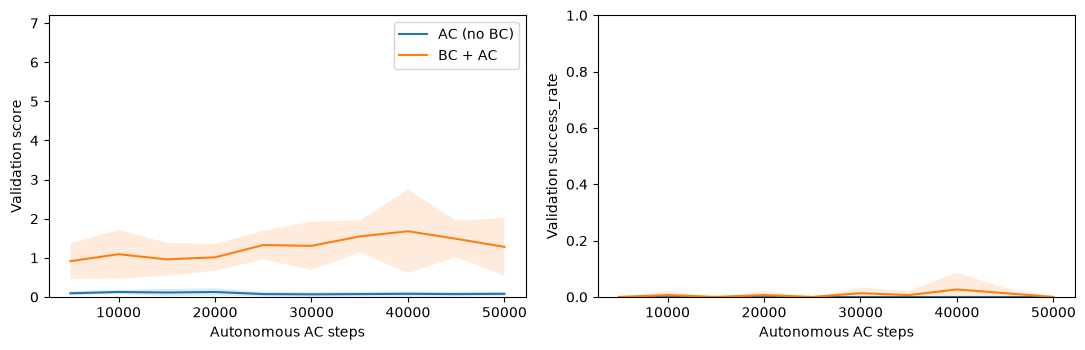

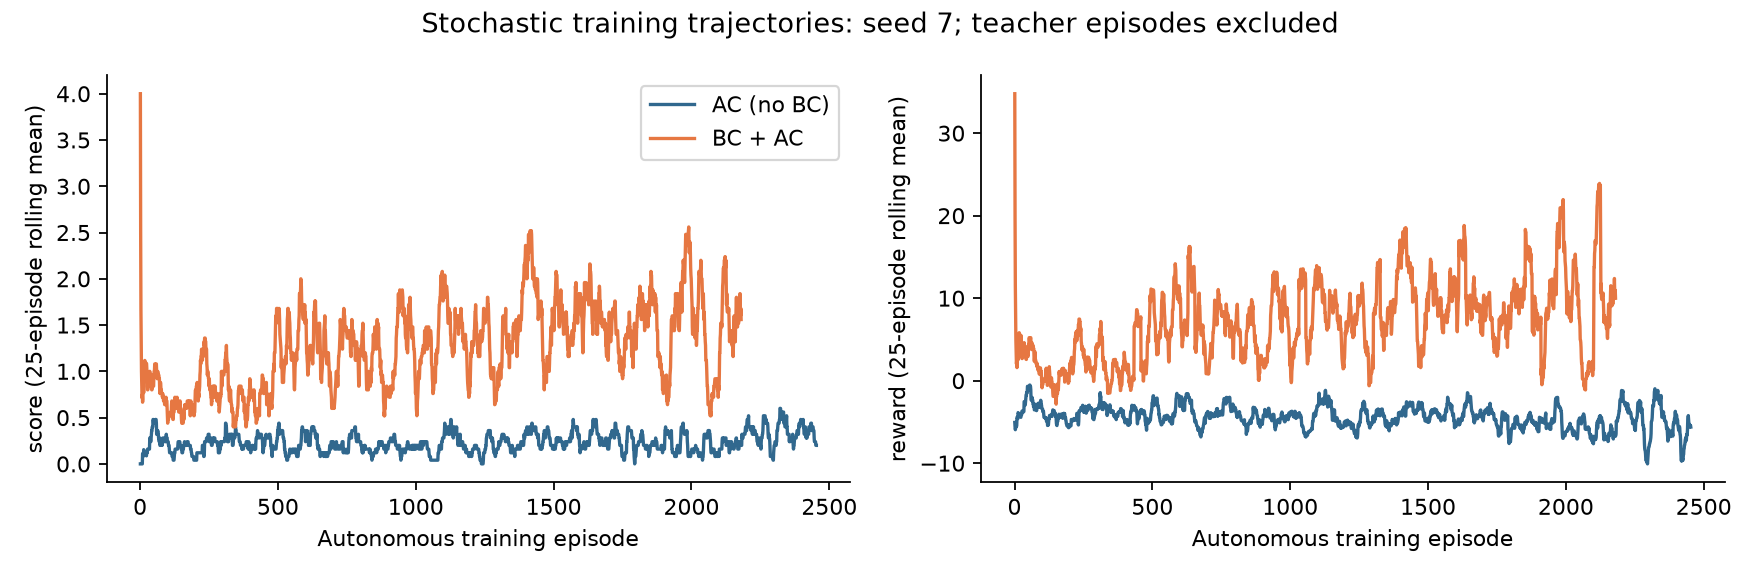

In [6]:
validation_ac = pd.read_csv(RESULT_DIR / 'all_validation.csv')
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for arm, label in [('ac', 'AC (no BC)'), ('bc_ac', 'BC + AC')]:
    selected = validation_ac.query("arm == @arm and stage == 'actor_critic'")
    for ax, metric in zip(axes, ['score', 'success_rate']):
        g = selected.groupby('rl_steps')[metric].agg(['mean', 'std'])
        ax.plot(g.index, g['mean'], label=label)
        ax.fill_between(g.index, g['mean']-g['std'], g['mean']+g['std'], alpha=.15)
        ax.set(xlabel='Autonomous AC steps', ylabel='Validation '+metric)
axes[0].set_ylim(0, 7.2); axes[1].set_ylim(0, 1); axes[0].legend()
plt.tight_layout(); plt.show()
display(NotebookImage(filename=str(RESULT_DIR / 'figures/training_reward_score.png')))

## 2.5 Evaluation and Paired Uncertainty

Each training seed is one experimental unit. The table and intervals below use saved held-out episodes; test outcomes never select a checkpoint. Read the standalone Markdown report for the complete interpretation.

,seed,arm,score,reward,success_rate,death_rate,truncation_rate
0,7,ac,0.135,-3.71865,0.000,1.000,0.000
1,7,bc_ac,1.910,-0.63385,0.020,0.495,0.485
2,42,ac,0.140,-3.67880,0.000,1.000,0.000
3,42,bc_ac,1.505,-12.74920,0.000,0.690,0.310
4,2026,ac,0.060,-4.44940,0.000,1.000,0.000
5,2026,bc_ac,1.675,1.87720,0.010,0.565,0.425
6,31415,ac,0.140,-3.67915,0.000,1.000,0.000
7,31415,bc_ac,1.820,6.61370,0.000,0.735,0.265
8,27182,ac,0.160,-3.61260,0.000,1.000,0.000
9,27182,bc_ac,1.430,-8.08700,0.005,0.700,0.295


score             reward           success_rate          
        mean       std     mean       std         mean       std
arm                                                             
ac     0.127  0.038665 -3.82772  0.349610        0.000  0.000000
bc_ac  1.668  0.203058 -2.59583  7.776835        0.007  0.008367

,mean_difference,bootstrap_95_low,bootstrap_95_high
score,1.54100,1.3710,1.70500
success_rate,0.00700,0.0010,0.01400
reward,1.23189,-5.0718,7.26474


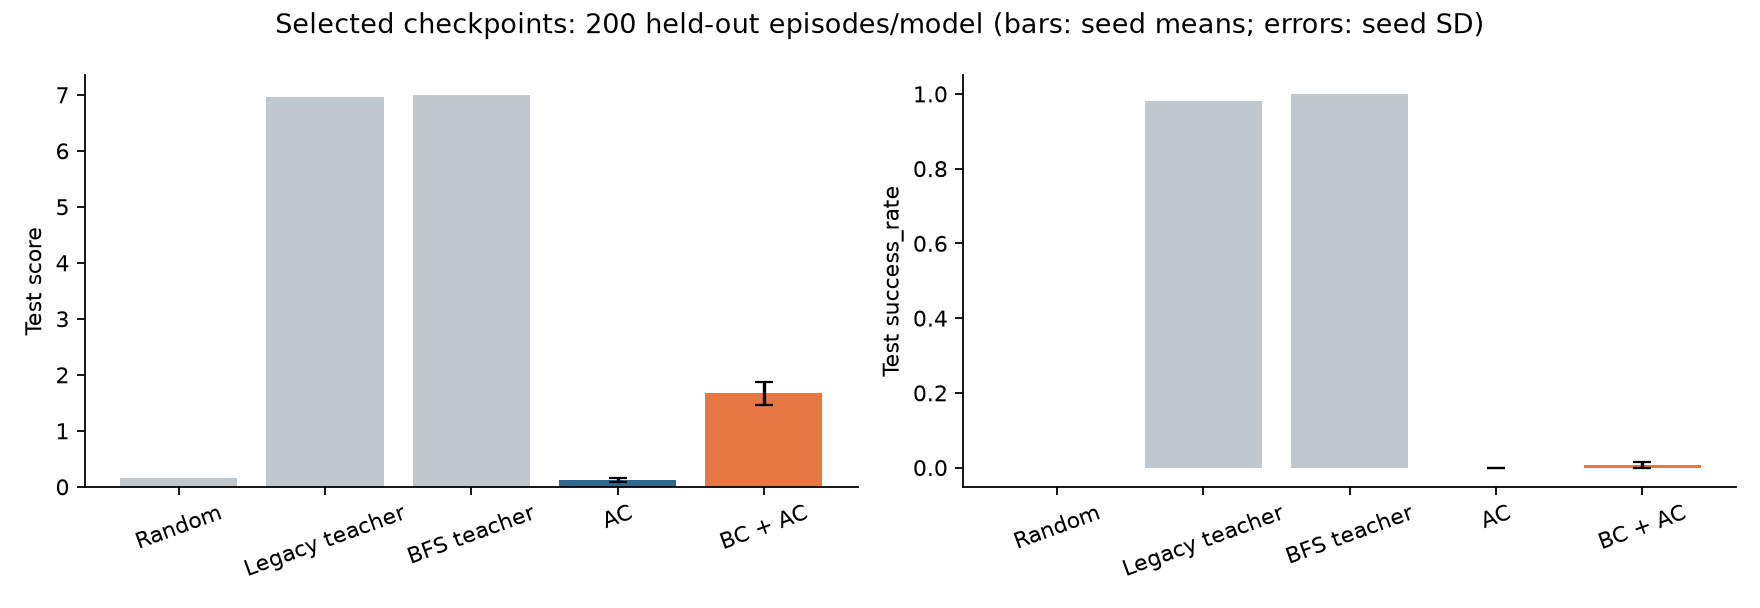

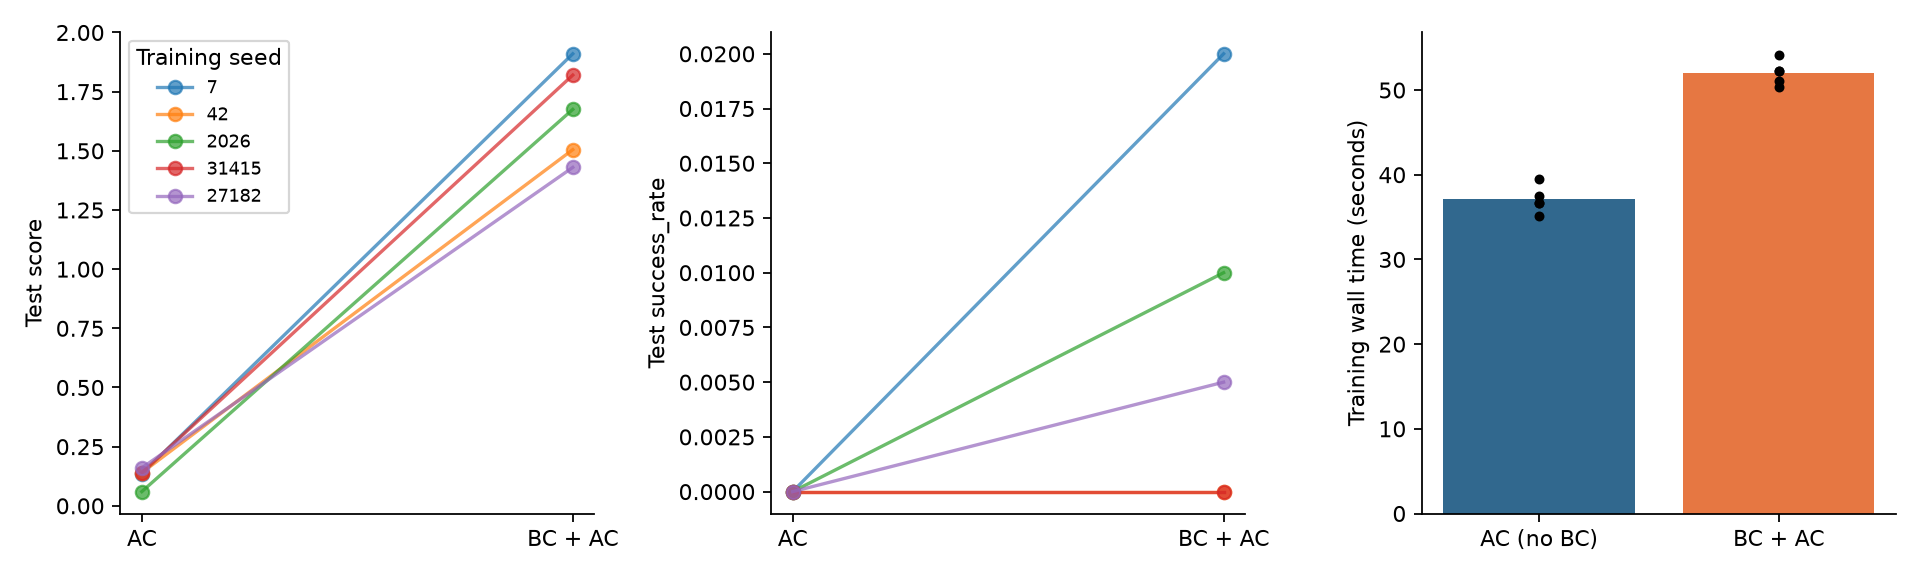

,seed,arm,rl_steps,demo_steps,total_steps,bc_updates,training_seconds,selected_rl_steps
0,7,ac,50000,0,50000,0,36.645753,5000
1,7,bc_ac,50000,3983,53983,15932,52.198993,50000
2,42,ac,50000,0,50000,0,35.099020,20000
3,42,bc_ac,50000,3896,53896,15584,50.365941,35000
4,2026,ac,50000,0,50000,0,39.466956,5000
5,2026,bc_ac,50000,3943,53943,15772,54.160298,40000
6,31415,ac,50000,0,50000,0,37.516242,10000
7,31415,bc_ac,50000,3873,53873,15492,51.027631,40000
8,27182,ac,50000,0,50000,0,36.695608,20000
9,27182,bc_ac,50000,3891,53891,15564,52.223577,25000


score  success_rate
arm   stage                       
ac    best     0.127         0.000
      latest   0.045         0.000
      post_bc  0.033         0.000
bc_ac best     1.668         0.007
      latest   1.121         0.005
      post_bc  1.218         0.010

In [7]:
per_seed_ac = pd.read_csv(RESULT_DIR / 'per_seed_results.csv')
display(per_seed_ac[['seed','arm','score','reward','success_rate','death_rate','truncation_rate']])
display(per_seed_ac.groupby('arm')[['score','reward','success_rate']].agg(['mean','std']))
uncertainty_ac = json.loads((RESULT_DIR / 'paired_results.json').read_text())
display(pd.DataFrame({key: {'mean_difference': value['mean_difference'],
                          'bootstrap_95_low': value['bootstrap_95'][0],
                          'bootstrap_95_high': value['bootstrap_95'][1]}
                      for key, value in uncertainty_ac.items()}).T)
display(NotebookImage(filename=str(RESULT_DIR / 'figures/final_performance.png')))
display(NotebookImage(filename=str(RESULT_DIR / 'figures/paired_outcomes_cost.png')))
display(pd.read_csv(RESULT_DIR / 'training_cost.csv'))
stage_ac = pd.read_csv(RESULT_DIR / 'stage_results.csv')
display(stage_ac.groupby(['arm','stage'])[['score','success_rate']].mean())

## 2.6 Visualizing Training Progress

The complete headless gameplay code from `play.py` is included below. The four stages share the predeclared game seed 900000 and training seed 7. Every panel is played solely by the network. A single GIF illustrates behavior; the multi-episode table supports performance claims.

In [8]:
"""Member 2: unassisted gameplay and headless, reproducible progress GIFs."""
from __future__ import annotations
import argparse
import json
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
from main import as_tensor, choose_device, load_agent, make_env


def rollout(checkpoint, seed=900000, device='cpu'):
    model, config = load_agent(checkpoint, device)
    env = make_env(config)
    frames = []
    def capture():
        return dict(snake=[x.tolist() for x in env.snake], food=env.food_pos.tolist(), score=env.score)
    try:
        obs, _ = env.reset(seed=seed)
        frames.append(capture())
        total = 0.0
        while True:
            action = model.predict(as_tensor(obs, model.device), deterministic=True)
            obs, reward, terminated, truncated, info = env.step(action)
            frames.append(capture())
            total += reward
            if terminated or truncated:
                return dict(seed=seed, frames=frames, grid_size=config.grid_size,
                            score=info['score'], steps=info['steps'], reward=total,
                            success=info['length'] >= config.end_score,
                            outcome='win' if info['length'] >= config.end_score else
                                    ('time limit' if truncated else 'collision'))
    finally:
        env.close()


def _font(size):
    for name in ['/System/Library/Fonts/Supplemental/Arial.ttf', 'DejaVuSans.ttf']:
        try:
            return ImageFont.truetype(name, size)
        except OSError:
            pass
    return ImageFont.load_default()


def board_image(record, frame_index, title, cell=27):
    grid = record['grid_size']
    width = grid*cell+24
    image = Image.new('RGB', (width, grid*cell+100), '#f4f6f8')
    draw = ImageDraw.Draw(image)
    frame = record['frames'][min(frame_index, len(record['frames'])-1)]
    draw.text((10, 8), title, font=_font(16), fill='#152e41')
    draw.text((10, 32), f"step {min(frame_index, record['steps'])} | score {frame['score']}", font=_font(14), fill='#152e41')
    for r in range(grid):
        for c in range(grid):
            draw.rectangle((12+c*cell, 60+r*cell, 12+(c+1)*cell, 60+(r+1)*cell), fill='white', outline='#dde3e8')
    for i, (r,c) in enumerate(frame['snake']):
        draw.rectangle((14+c*cell, 62+r*cell, 10+(c+1)*cell, 58+(r+1)*cell), fill='#173d59' if i==0 else '#3e9b8a')
    r,c = frame['food']
    draw.ellipse((17+c*cell, 65+r*cell, 7+(c+1)*cell, 55+(r+1)*cell), fill='#e56353')
    if frame_index >= record['steps']:
        draw.text((12, grid*cell+68), f"{record['outcome']} | final score {record['score']}", font=_font(13), fill='#152e41')
    return image


def render_progress(checkpoints, output, seed=900000):
    """Same predeclared seed for every stage; finished games freeze in place."""
    output = Path(output)
    output.parent.mkdir(parents=True, exist_ok=True)
    records = {label: rollout(path, seed) for label, path in checkpoints.items()}
    max_steps = max(x['steps'] for x in records.values())
    frames = []
    for step in list(range(0, max_steps+1, 2)) + [max_steps]*8:
        panels = [board_image(rec, step, label) for label,rec in records.items()]
        canvas = Image.new('RGB', (sum(p.width for p in panels), max(p.height for p in panels)), 'white')
        pos = 0
        for p in panels:
            canvas.paste(p, (pos, 0)); pos += p.width
        frames.append(canvas)
    frames[0].save(output, save_all=True, append_images=frames[1:], duration=120, loop=0)
    frames[-1].save(output.with_suffix('.png'))
    output.with_suffix('.json').write_text(json.dumps(records, indent=2))
    return {k:{n:v for n,v in rec.items() if n != 'frames'} for k,rec in records.items()}


def play_game(model_path, *, device_name='auto', seed=42, fps=15):
    model, config = load_agent(model_path, choose_device(device_name))
    env = make_env(config, render_mode='human')
    try:
        obs, _ = env.reset(seed=seed)
        while not env.closed:
            action = model.predict(as_tensor(obs, model.device), deterministic=True)
            obs, _, terminated, truncated, info = env.step(action)
            env.render(fps=fps)
            if terminated or truncated:
                print(info)
                break
    finally:
        env.close()

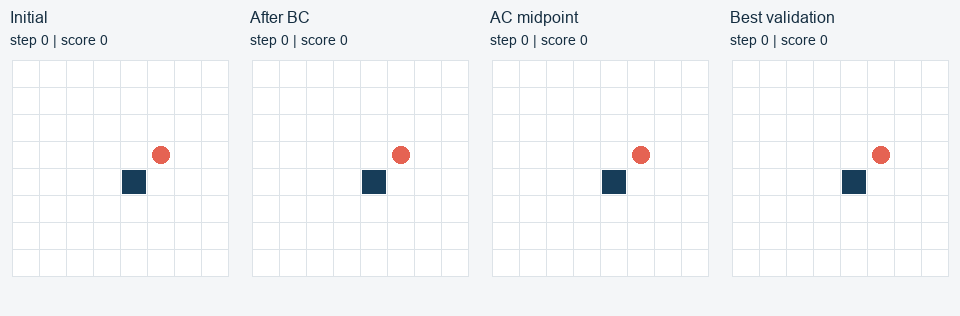

,seed,grid_size,score,steps,reward,success,outcome
Initial,900000,8,0,300,-150.5,False,time limit
After BC,900000,8,1,9,4.93,False,collision
AC midpoint,900000,8,1,11,4.91,False,collision
Best validation,900000,8,1,300,-17.49,False,time limit


In [9]:
display(NotebookImage(filename=str(RESULT_DIR / 'figures/training_progress.gif')))
progress_ac = json.loads((RESULT_DIR / 'figures/training_progress.json').read_text())
display(pd.DataFrame({label: {k:v for k,v in record.items() if k != 'frames'}
                      for label,record in progress_ac.items()}).T)
# To regenerate from actual checkpoints, run:
# python member2_experiment.py --mode analysis

## 2.7 Limitations and Interpretation

1. **Additional supervision.** BC + AC sees teacher-selected actions and has additional demonstration and optimizer costs. An equal-total-transition or equal-wall-time comparison would answer a different question.
2. **Small number of independent training runs.** Five paired seeds reveal variation but support only limited generalization. Episode-level averages do not replace training-seed replication.
3. **Limited board and budget.** We use one 8 × 8 environment, one parameter setting, and 50,000 RL steps. These numbers cannot be directly compared with Member 3's 210,000-step DQN experiment as a ranking of algorithms. Member 5 should rerun a shared protocol for group-wide comparisons.
4. **Representation and optimization limits.** The inherited seven-channel observation does not explicitly encode head identity, ordered body segments, loop-history or remaining time. It is not a fully Markov state for every reward/termination feature. A one-step bootstrapped critic, shared features and sparse large terminal rewards can produce unstable policy updates. BC also exposes the model mainly to teacher-visited states, so mistakes can move it to unfamiliar states.
5. **No automatic strongest-agent claim.** Learning is judged by autonomous held-out score and success, not teacher trajectories or training loss alone. The teacher remains a demanding reference on this small board.

Possible follow-up work is to test richer observations, longer or multi-step returns, or conservative policy updates on validation seeds, then reserve a new test range. These are future experiments, not completed results in this section.

## 2.8 Reproduction and Integration

- `python member2_experiment.py --mode smoke`: small pipeline check in a separate directory.
- `python member2_experiment.py --mode final`: reproduce or reuse the completed five-seed experiment in `runs/member2/final`.
- `python member2_experiment.py --mode analysis`: regenerate aggregate tables, figures and the fixed-seed GIF from saved logs and checkpoints.
- `python gen_notebook.py`: regenerate this Markdown report, the standalone Member 2 notebook, and the group notebook with only Section 2 replaced.
- `python test_member2.py`: check terminal targets, explicit BC actions, no teacher leakage in AC/evaluation, exact RL budgets, paired initialization and checkpoint loading.

The notebook defaults to `TRAIN_MODEL = False`, loads saved weights and reruns independent inference without training. `history.csv`, `validation.csv`, `test_episodes.csv`, saved checkpoints, `protocol.json`, source hashes and runtime versions accompany the report. Completed runs are reused only with a matching protocol and source hash; incomplete runs are rerun from scratch. Exact mid-run resume is explicitly unsupported.

`ConvActorCritic`, `TrainConfig`, `train`, `as_tensor`, `choose_device` and the original checkpoint dictionary keys remain available for the group benchmark. The group's defaults can still run the episode-based training interface. Files belonging to Members 3 and 4 are unchanged support copies; their report sections remain their responsibility.

## 2.9 Contribution and Generative AI Disclosure

Member 2's deliverables comprise the Actor-Critic/BC implementation, paired ablation, checkpoints and raw evidence, learning and gameplay visualizations, and the completed Section 2 report and notebook cells. Environment and teacher authorship remains with Member 1. No student name or ID has been inferred.

OpenAI Codex (generative AI) assisted with code implementation, debugging, experiment design, notebook integration and report drafting. The included results were produced by executing the supplied programs; they are not illustrative or fabricated numbers. This disclosure covers Member 2's work only. The group must consolidate all members' actual AI use in its final declaration. The human presenter should verify and understand the implementation and results before presenting them.

## References

- [Group source notebook and original framework](https://github.com/Allepsilon-0/DSA5102-Final-Group-Project/blob/main/Snake/DSA5102_final_project_snake.ipynb).
- [OpenAI Spinning Up: policy optimization and advantage functions](https://spinningup.openai.com/en/latest/spinningup/rl_intro3.html). Conceptual background; this project implements one-step TD Actor-Critic rather than Spinning Up's GAE-based VPG training loop.
- [Gymnasium: handling time limits](https://gymnasium.farama.org/v1.1.1/tutorials/gymnasium_basics/handling_time_limits/). Source for distinguishing termination from truncation in bootstrap targets.

### Complete recorded findings

The following saved report contains the numerical interpretation and all limitations. It is generated from the same raw files shown above.

In [10]:
from IPython.display import Markdown
report_ac = (HERE / 'member2_section2.md').read_text(encoding='utf-8')
# Display the numerical findings; images are already displayed above.
findings_ac = '## 2.5 Held-Out Gameplay Results' + report_ac.split('## 2.5 Held-Out Gameplay Results')[1].split('## 2.6 Visualizing Training Progress')[0]
import re
findings_ac = re.sub(r'!\[[^\]]*\]\([^)]*\)', '', findings_ac)
display(Markdown(findings_ac))

## 2.5 Held-Out Gameplay Results

The following are means ± **sample standard deviation across the five training seeds**. Each seed's value is first averaged over its 200 test episodes.

| Learned method | Score (max 7) | Success rate | Reward |
|---|---:|---:|---:|
| Actor-Critic (no BC) | 0.127 ± 0.039 | 0.0% ± 0.0% | -3.828 ± 0.350 |
| BC + Actor-Critic | 1.668 ± 0.203 | 0.7% ± 0.8% | -2.596 ± 7.777 |

The independently rerun references on the same test seeds are: Random score **0.165**, legacy teacher **6.965**, BFS teacher **7.000**. The teachers are strong heuristic references, not theoretical upper bounds. These are Member 2's reruns rather than copied figures from Members 1 or 3.

AC from scratch does not exceed the independently rerun Random mean score at this budget. The BC + AC mean score is 1.668 out of 7, so the learned policy still has a substantial gap to the BFS teacher. The experiment therefore supports a narrowly defined initialization benefit rather than a claim that this small AC model solves Snake.



*Only learned methods have cross-training-seed error bars. A missing baseline error bar does not imply zero episode variation; each baseline has one 200-episode evaluation.*

### Paired seed outcomes and uncertainty

| Training seed | AC score | BC + AC score | Difference |
|---:|---:|---:|---:|
| 7 | 0.135 | 1.910 | +1.775 |
| 42 | 0.140 | 1.505 | +1.365 |
| 2026 | 0.060 | 1.675 | +1.615 |
| 31415 | 0.140 | 1.820 | +1.680 |
| 27182 | 0.160 | 1.430 | +1.270 |

We bootstrap the five **paired training-seed differences** 20,000 times, with fixed bootstrap seed 20261019. Test episodes are not treated as 1,000 independent training runs. These small-sample bootstrap intervals describe uncertainty under this experiment and have limited coverage guarantees with only five seeds.

| Outcome | BC + AC minus AC | Paired bootstrap 95% interval |
|---|---:|---:|
| Mean score | +1.541 | [1.371, 1.705] |
| Success rate (percentage points) | +0.700 | [0.100, 1.400] |
| Reward | +1.232 | [-5.072, 7.265] |

The paired score interval is above zero in these runs. This supports a benefit from BC under this fixed protocol; it does not establish general superiority across tasks or hyperparameters.

The win rate nevertheless remains only **0.7%**. Mean reward changes by **+1.232**, with interval **[-5.072, 7.265]**, which includes zero. Thus the score gain is clearer than either reliable winning or improved total reward. Longer survival can accumulate loop and step penalties without eating more food; higher food score alone does not guarantee higher shaped return.

| Condition | Death rate | Time-limit truncation rate | Success rate |
|---|---:|---:|---:|
| AC | 100.0% | 0.0% | 0.0% |
| BC + AC | 63.7% | 35.6% | 0.7% |



### Does later RL improve the BC initialization?

The independently tested BC-only snapshot has mean score **1.218** and success rate **1.0%** across the five seeds. The last BC + AC snapshot has mean score **1.121** and success rate **0.5%**. The validation-selected BC + AC result above is a third, separately defined outcome. Selected AC steps by seed are **7: 50,000, 42: 35,000, 2026: 40,000, 31415: 40,000, 27182: 25,000**.

These stage results separate learning from demonstrations, continued RL, and validation-based checkpoint selection. Validation-selected best performance must not be described as the guaranteed performance of the last update. In particular, a gain over AC from scratch does not by itself prove that RL improves every BC-only policy.

